In [1]:
import socket
import struct
import numpy as np
import cv2
import time
import sys
from pynq import Overlay, allocate

print("Initializing Video Pipeline Overlay...")
try:
    overlay = Overlay("/home/xilinx/pynq/overlays/NiraGarage/ISP/design_1_wrapper.bit")
    dma = overlay.axi_dma_0
    isp_ip = overlay.isp_hls_top_0
    
    dma.recvchannel._max_size = 8388607
    dma.sendchannel._max_size = 8388607
    
    try: isp_ip.write(0x10, 16) 
    except: print("Warning: Gain register unreachable.")
except Exception as e:
    print(f"FPGA Initialization Error: {e}")
    exit(1)

width, height = 1280, 720

print("Allocating zero-copy physical hardware memory buffers...")
in_buffer = allocate(shape=(height, width), dtype=np.uint32)
out_buffer = allocate(shape=(height, width), dtype=np.uint32)

server_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
server_socket.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
server_socket.bind(('0.0.0.0', 9999)) 
server_socket.listen(1)

print("PYNQ LIVE HARDWARE SERVER ACTIVE: Waiting for connection...")

def recv_all(sock, count):
    buf = b''
    while count:
        newbuf = sock.recv(count)
        if not newbuf: return None
        buf += newbuf
        count -= len(newbuf)
    return buf

try:
    conn, addr = server_socket.accept()
    print(f"Connected to client: {addr}")
    
    bayer_data = np.zeros((height, width), dtype=np.uint8)
    latency_records = []
    
    while True:
        size_header = recv_all(conn, 4)
        if not size_header: break 
        size = struct.unpack(">I", size_header)[0]
        
        if size == 0xFFFFFFFF:
            print("Received termination signal from client.")
            break
            
        jpeg_data = recv_all(conn, size)
        if not jpeg_data: break
        
        np_arr = np.frombuffer(jpeg_data, dtype=np.uint8)
        img_resized = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)
        if img_resized is None: continue

        # Bayer Simulation ---
        bayer_data[0::2, 0::2] = img_resized[0::2, 0::2, 2] 
        bayer_data[0::2, 1::2] = img_resized[0::2, 1::2, 1] 
        bayer_data[1::2, 0::2] = img_resized[1::2, 0::2, 1] 
        bayer_data[1::2, 1::2] = img_resized[1::2, 1::2, 0] 

        # DMA Ingestion & HW Acceleration ---
        t_start = time.time()
        in_buffer[:] = bayer_data.astype(np.uint32)

        isp_ip.write(0x00, 0x1) 
        dma.recvchannel.transfer(out_buffer)
        dma.sendchannel.transfer(in_buffer)
        dma.sendchannel.wait()
        dma.recvchannel.wait()

        latency_ms = (time.time() - t_start) * 1000
        latency_records.append(latency_ms)

        # Format output (RGB Layout to BGR) ---
        raw_output = out_buffer.view(np.uint8).reshape(height, width, 4)
        final_image_rgb = raw_output[:, :, 0:3].copy() 
        final_image_bgr = cv2.cvtColor(final_image_rgb, cv2.COLOR_RGB2BGR)
        
        current_fps = 1000.0 / latency_ms if latency_ms > 0 else 0.0

        cv2.putText(final_image_bgr, f"FPGA ISP Latency: {latency_ms:.1f}ms | {current_fps:.1f} FPS", (30, 50), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2, cv2.LINE_AA)

        # Transmit Packets ---
        ret, encoded_out = cv2.imencode('.jpg', final_image_bgr, [int(cv2.IMWRITE_JPEG_QUALITY), 75])
        out_bytes = encoded_out.tobytes()
        conn.sendall(struct.pack(">I", len(out_bytes)) + out_bytes)

    if latency_records:
        avg_latency = sum(latency_records) / len(latency_records)
        avg_fps = 1000.0 / avg_latency if avg_latency > 0 else 0.0
        print(f"Total Frames Processed: {len(latency_records)}")
        print(f"Average Hardware Latency: {avg_latency:.2f} ms")
        print(f"Average Hardware Pipeline FPS: {avg_fps:.2f} FPS")

except KeyboardInterrupt:
    print("Shutting down stream pipelines.")
finally:
    conn.close()
    server_socket.close()
    in_buffer.close()
    out_buffer.close()
    print("Hardware resources released. Exiting server.")
    sys.exit(0)

Initializing Video Pipeline Overlay...


Allocating zero-copy physical hardware memory buffers...
PYNQ LIVE HARDWARE SERVER ACTIVE: Waiting for connection...
Connected to client: ('192.168.2.1', 59626)
Received termination signal from client.
Total Frames Processed: 222
Average Hardware Latency: 35.28 ms
Average Hardware Pipeline FPS: 28.34 FPS
Hardware resources released. Exiting server.


SystemExit: 0

/usr/local/share/pynq-venv/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3406: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


Initializing Video Pipeline Overlay for Stored MP4...



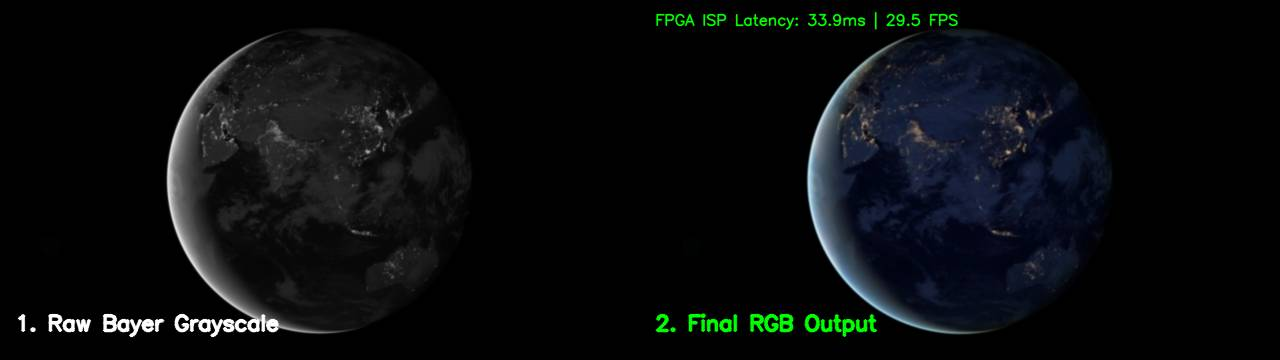


Running Headless FIFO Player... View output directly in Jupyter browser cell.
Background Hardware Processing Thread Started...

Terminated by operator.

================ BENCHMARK RESULTS ================
Total Frames Processed: 32
Average Hardware Latency: 35.43 ms
Average Hardware Pipeline FPS: 28.22 FPS


In [2]:
import cv2
import numpy as np
import time
import sys
import threading
import queue
import base64
from pynq import Overlay, allocate
from IPython.display import display, HTML

# Configuration parameters
VIDEO_INPUT_PATH = "/home/xilinx/pynq/overlays/NiraGarage/VPC/input.mp4"
width, height = 1280, 720
FIFO_MAX_SIZE = 30  

print("Initializing Video Pipeline Overlay for Stored MP4...")
try:
    overlay = Overlay("/home/xilinx/pynq/overlays/NiraGarage/ISP/design_1_wrapper.bit")
    dma = overlay.axi_dma_0
    isp_ip = overlay.isp_hls_top_0
    
    dma.recvchannel._max_size = 8388607
    dma.sendchannel._max_size = 8388607
    
    try: isp_ip.write(0x10, 16) 
    except: print("Warning: Gain register unreachable.")
except Exception as e:
    print(f"FPGA Initialization Error: {e}")
    sys.exit(1)

frame_fifo = queue.Queue(maxsize=FIFO_MAX_SIZE)
pipeline_running = True
latency_records = []

def hw_processing_worker():
    global pipeline_running, latency_records
    
    cap = cv2.VideoCapture(VIDEO_INPUT_PATH, cv2.CAP_FFMPEG)
    if not cap.isOpened():
        print(f"Error: Could not open input video file at {VIDEO_INPUT_PATH}")
        pipeline_running = False
        return

    in_buffer = allocate(shape=(height, width), dtype=np.uint32)
    out_buffer = allocate(shape=(height, width), dtype=np.uint32)
    bayer_data = np.zeros((height, width), dtype=np.uint8)

    print("Background Hardware Processing Thread Started...")
    
    while cap.isOpened() and pipeline_running:
        ret, frame = cap.read()
        if not ret:
            cap.set(cv2.CAP_PROP_POS_FRAMES, 0) # Loop source asset dynamically
            continue  

        frame_resized = cv2.resize(frame, (width, height))

        # Bayer Simulation ---
        bayer_data[0::2, 0::2] = frame_resized[0::2, 0::2, 2] 
        bayer_data[0::2, 1::2] = frame_resized[0::2, 1::2, 1] 
        bayer_data[1::2, 0::2] = frame_resized[1::2, 0::2, 1] 
        bayer_data[1::2, 1::2] = frame_resized[1::2, 1::2, 0] 

        bayer_g_3ch = cv2.cvtColor(bayer_data, cv2.COLOR_GRAY2BGR)

        # Ingestion & HW Acceleration ---
        t_start = time.time()
        in_buffer[:] = bayer_data.astype(np.uint32)

        isp_ip.write(0x00, 0x1) 
        dma.recvchannel.transfer(out_buffer)
        dma.sendchannel.transfer(in_buffer)
        dma.sendchannel.wait()
        dma.recvchannel.wait()

        latency_ms = (time.time() - t_start) * 1000
        latency_records.append(latency_ms)

        # Format output ---
        raw_output = out_buffer.view(np.uint8).reshape(height, width, 4)
        final_image_rgb = raw_output[:, :, 0:3].copy() 
        final_image_bgr = cv2.cvtColor(final_image_rgb, cv2.COLOR_RGB2BGR)
        
        current_fps = 1000.0 / latency_ms if latency_ms > 0 else 0.0

        cv2.putText(final_image_bgr, f"FPGA ISP Latency: {latency_ms:.1f}ms | {current_fps:.1f} FPS", (30, 50), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2, cv2.LINE_AA)

        # Side-by-Side Display Layout ---
        display_left = cv2.resize(bayer_g_3ch, (640, 360))
        display_right = cv2.resize(final_image_bgr, (640, 360))
        
        cv2.putText(display_left, "1. Raw Bayer Grayscale", (15, 330), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(display_right, "2. Final RGB Output", (15, 330), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2, cv2.LINE_AA)

        combined_view = np.hstack((display_left, display_right))
        
        ret, encoded_image = cv2.imencode('.jpg', combined_view, [int(cv2.IMWRITE_JPEG_QUALITY), 70])
        if ret:
            try:
                if frame_fifo.full():
                    try: frame_fifo.get_nowait()
                    except queue.Empty: pass
                frame_fifo.put_nowait(encoded_image.tobytes())
            except Exception:
                pass
        
        time.sleep(0.01)

    cap.release()
    in_buffer.close()
    out_buffer.close()

worker_thread = threading.Thread(target=hw_processing_worker)
worker_thread.daemon = True
worker_thread.start()

html_handle = display(HTML(""), display_id="hw_fifo_live_view")

print("\nRunning Headless FIFO Player... View output directly in Jupyter browser cell.")
try:
    while pipeline_running:
        try:
            jpeg_bytes = frame_fifo.get(timeout=1.0)
        except queue.Empty:
            if not worker_thread.is_alive():
                break
            continue

        b64_str = base64.b64encode(jpeg_bytes).decode('utf-8')
        html_handle.update(HTML(f'<img src="data:image/jpeg;base64,{b64_str}" style="width:100%; max-width:1280px;"/>'))
        time.sleep(0.02)

except KeyboardInterrupt:
    print("\nTerminated by operator.")
finally:
    pipeline_running = False
    worker_thread.join(timeout=2.0)
    
    print("\n================ BENCHMARK RESULTS ================")
    if latency_records:
        avg_latency = sum(latency_records) / len(latency_records)
        avg_fps = 1000.0 / avg_latency if avg_latency > 0 else 0.0
        print(f"Total Frames Processed: {len(latency_records)}")
        print(f"Average Hardware Latency: {avg_latency:.2f} ms")
        print(f"Average Hardware Pipeline FPS: {avg_fps:.2f} FPS")
    print("===================================================")

In [3]:
import cv2
import numpy as np
import time
import sys
import threading
import queue
from pynq import Overlay, allocate

# Configuration parameters
VIDEO_INPUT_PATH = "/home/xilinx/pynq/overlays/NiraGarage/VPC/input.mp4"
width, height = 1280, 720
FIFO_MAX_SIZE = 2  # Tiny queue prevents frame buffering lag

print("Initializing Video Pipeline Overlay for Stored MP4...")
try:
    overlay = Overlay("/home/xilinx/pynq/overlays/NiraGarage/ISP/design_1_wrapper.bit")
    dma = overlay.axi_dma_0
    isp_ip = overlay.isp_hls_top_0
    
    dma.recvchannel._max_size = 8388607
    dma.sendchannel._max_size = 8388607
    
    try: isp_ip.write(0x10, 16) 
    except: print("Warning: Gain register unreachable.")
except Exception as e:
    print(f"FPGA Initialization Error: {e}")
    sys.exit(1)

frame_fifo = queue.Queue(maxsize=FIFO_MAX_SIZE)
pipeline_running = True
latency_records = []

def hw_processing_worker():
    global pipeline_running, latency_records
    
    cap = cv2.VideoCapture(VIDEO_INPUT_PATH, cv2.CAP_FFMPEG)
    if not cap.isOpened():
        print(f"Error: Could not open input video file at {VIDEO_INPUT_PATH}")
        pipeline_running = False
        return

    in_buffer = allocate(shape=(height, width), dtype=np.uint32)
    out_buffer = allocate(shape=(height, width), dtype=np.uint32)
    bayer_data = np.zeros((height, width), dtype=np.uint8)

    print("Background Hardware Processing Thread Started...")
    
    while cap.isOpened() and pipeline_running:
        ret, frame = cap.read()
        if not ret:
            cap.set(cv2.CAP_PROP_POS_FRAMES, 0) # Loop source asset dynamically
            continue  

        frame_resized = cv2.resize(frame, (width, height))

        # --- STEP 1: Bayer Simulation ---
        bayer_data[0::2, 0::2] = frame_resized[0::2, 0::2, 2] 
        bayer_data[0::2, 1::2] = frame_resized[0::2, 1::2, 1] 
        bayer_data[1::2, 0::2] = frame_resized[1::2, 0::2, 1] 
        bayer_data[1::2, 1::2] = frame_resized[1::2, 1::2, 0] 

        bayer_g_3ch = cv2.cvtColor(bayer_data, cv2.COLOR_GRAY2BGR)

        # --- STEP 2: Ingestion & HW Acceleration ---
        t_start = time.time()
        in_buffer[:] = bayer_data.astype(np.uint32)

        isp_ip.write(0x00, 0x1) 
        dma.recvchannel.transfer(out_buffer)
        dma.sendchannel.transfer(in_buffer)
        dma.sendchannel.wait()
        dma.recvchannel.wait()

        latency_ms = (time.time() - t_start) * 1000
        latency_records.append(latency_ms)

        # --- STEP 3: Format output ---
        raw_output = out_buffer.view(np.uint8).reshape(height, width, 4)
        final_image_rgb = raw_output[:, :, 0:3].copy() 
        final_image_bgr = cv2.cvtColor(final_image_rgb, cv2.COLOR_RGB2BGR)
        
        current_fps = 1000.0 / latency_ms if latency_ms > 0 else 0.0

        cv2.putText(final_image_bgr, f"FPGA ISP Latency: {latency_ms:.1f}ms | {current_fps:.1f} FPS", (30, 50), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2, cv2.LINE_AA)

        # --- STEP 4: Side-by-Side Display Layout ---
        display_left = cv2.resize(bayer_g_3ch, (640, 360))
        display_right = cv2.resize(final_image_bgr, (640, 360))
        
        cv2.putText(display_left, "1. Raw Bayer Grayscale", (15, 330), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(display_right, "2. Final RGB Output", (15, 330), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2, cv2.LINE_AA)

        combined_view = np.hstack((display_left, display_right))
        
        # --- STEP 5: Push raw frame directly to queue (Zero Compression Overhead) ---
        try:
            if frame_fifo.full():
                try: frame_fifo.get_nowait()
                except queue.Empty: pass
            frame_fifo.put_nowait(combined_view)
        except Exception:
            pass

    cap.release()
    in_buffer.close()
    out_buffer.close()

# Initialize worker thread
worker_thread = threading.Thread(target=hw_processing_worker)
worker_thread.daemon = True
worker_thread.start()

print("\nRunning Optimized Native Streamer... Press 'q' in the video window to quit.")
try:
    while pipeline_running:
        try:
            frame_to_show = frame_fifo.get(timeout=1.0)
        except queue.Empty:
            if not worker_thread.is_alive():
                break
            continue

        cv2.imshow("FPGA Accelerated Pipeline - Optimized", frame_to_show)
        
        # Exit condition ('q' key)
        if cv2.waitKey(1) & 0xFF == ord('q'):
            print("Termination requested by user.")
            break

except KeyboardInterrupt:
    print("\nTerminated by operator.")
finally:
    pipeline_running = False
    worker_thread.join(timeout=2.0)
    cv2.destroyAllWindows()
    
    print("\n================ BENCHMARK RESULTS ================")
    if latency_records:
        avg_latency = sum(latency_records) / len(latency_records)
        avg_fps = 1000.0 / avg_latency if avg_latency > 0 else 0.0
        print(f"Total Frames Processed: {len(latency_records)}")
        print(f"Average Hardware Latency: {avg_latency:.2f} ms")
        print(f"Average Hardware Pipeline FPS: {avg_fps:.2f} FPS")
    print("===================================================")

Initializing Video Pipeline Overlay for Stored MP4...

Running Optimized Native Streamer... Press 'q' in the video window to quit.
Background Hardware Processing Thread Started...

================ BENCHMARK RESULTS ================
Total Frames Processed: 2
Average Hardware Latency: 34.99 ms
Average Hardware Pipeline FPS: 28.58 FPS


error: OpenCV(4.5.4) ./modules/highgui/src/window_gtk.cpp:635: error: (-2:Unspecified error) Can't initialize GTK backend in function 'cvInitSystem'


In [4]:
import cv2
import numpy as np
import time
import sys
import threading
import queue
import ipywidgets as widgets
from IPython.display import display
from pynq import Overlay, allocate

# Configuration parameters
VIDEO_INPUT_PATH = "/home/xilinx/pynq/overlays/NiraGarage/VPC/input.mp4"
width, height = 1280, 720
FIFO_MAX_SIZE = 2  # Tiny queue prevents frame buffering lag

print("Initializing Video Pipeline Overlay for Stored MP4...")
try:
    overlay = Overlay("/home/xilinx/pynq/overlays/NiraGarage/ISP/design_1_wrapper.bit")
    dma = overlay.axi_dma_0
    isp_ip = overlay.isp_hls_top_0
    
    dma.recvchannel._max_size = 8388607
    dma.sendchannel._max_size = 8388607
    
    try: isp_ip.write(0x10, 16) 
    except: print("Warning: Gain register unreachable.")
except Exception as e:
    print(f"FPGA Initialization Error: {e}")
    sys.exit(1)

frame_fifo = queue.Queue(maxsize=FIFO_MAX_SIZE)
pipeline_running = True
latency_records = []

def hw_processing_worker():
    global pipeline_running, latency_records
    
    cap = cv2.VideoCapture(VIDEO_INPUT_PATH, cv2.CAP_FFMPEG)
    if not cap.isOpened():
        print(f"Error: Could not open input video file at {VIDEO_INPUT_PATH}")
        pipeline_running = False
        return

    in_buffer = allocate(shape=(height, width), dtype=np.uint32)
    out_buffer = allocate(shape=(height, width), dtype=np.uint32)
    bayer_data = np.zeros((height, width), dtype=np.uint8)

    print("Background Hardware Processing Thread Started...")
    
    while cap.isOpened() and pipeline_running:
        ret, frame = cap.read()
        if not ret:
            cap.set(cv2.CAP_PROP_POS_FRAMES, 0) # Loop source asset dynamically
            continue  

        frame_resized = cv2.resize(frame, (width, height))

        # --- STEP 1: Bayer Simulation ---
        bayer_data[0::2, 0::2] = frame_resized[0::2, 0::2, 2] 
        bayer_data[0::2, 1::2] = frame_resized[0::2, 1::2, 1] 
        bayer_data[1::2, 0::2] = frame_resized[1::2, 0::2, 1] 
        bayer_data[1::2, 1::2] = frame_resized[1::2, 1::2, 0] 

        bayer_g_3ch = cv2.cvtColor(bayer_data, cv2.COLOR_GRAY2BGR)

        # --- STEP 2: Ingestion & HW Acceleration ---
        t_start = time.time()
        in_buffer[:] = bayer_data.astype(np.uint32)

        isp_ip.write(0x00, 0x1) 
        dma.recvchannel.transfer(out_buffer)
        dma.sendchannel.transfer(in_buffer)
        dma.sendchannel.wait()
        dma.recvchannel.wait()

        latency_ms = (time.time() - t_start) * 1000
        latency_records.append(latency_ms)

        # --- STEP 3: Format output ---
        raw_output = out_buffer.view(np.uint8).reshape(height, width, 4)
        final_image_rgb = raw_output[:, :, 0:3].copy() 
        final_image_bgr = cv2.cvtColor(final_image_rgb, cv2.COLOR_RGB2BGR)
        
        current_fps = 1000.0 / latency_ms if latency_ms > 0 else 0.0

        cv2.putText(final_image_bgr, f"FPGA ISP Latency: {latency_ms:.1f}ms | {current_fps:.1f} FPS", (30, 50), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2, cv2.LINE_AA)

        # --- STEP 4: Side-by-Side Display Layout ---
        display_left = cv2.resize(bayer_g_3ch, (640, 360))
        display_right = cv2.resize(final_image_bgr, (640, 360))
        
        cv2.putText(display_left, "1. Raw Bayer Grayscale", (15, 330), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(display_right, "2. Final RGB Output", (15, 330), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2, cv2.LINE_AA)

        combined_view = np.hstack((display_left, display_right))
        
        # Fast JPEG encoding for web widget transport
        ret, encoded_image = cv2.imencode('.jpg', combined_view, [int(cv2.IMWRITE_JPEG_QUALITY), 70])
        if ret:
            try:
                if frame_fifo.full():
                    try: frame_fifo.get_nowait()
                    except queue.Empty: pass
                frame_fifo.put_nowait(encoded_image.tobytes())
            except Exception:
                pass

    cap.release()
    in_buffer.close()
    out_buffer.close()

# Initialize worker thread
worker_thread = threading.Thread(target=hw_processing_worker)
worker_thread.daemon = True
worker_thread.start()

# Setup ipywidgets Image component for high-performance Jupyter streaming
img_widget = widgets.Image(format='jpeg', width=1280, height=360)
display(img_widget)

print("\nRunning Optimized Jupyter Widget Streamer... Interrupt kernel execution to stop.")
try:
    while pipeline_running:
        try:
            jpeg_bytes = frame_fifo.get(timeout=1.0)
        except queue.Empty:
            if not worker_thread.is_alive():
                break
            continue

        # Directly update widget value with raw bytes (no slow base64 DOM re-renders)
        img_widget.value = jpeg_bytes

except KeyboardInterrupt:
    print("\nTerminated by operator.")
finally:
    pipeline_running = False
    worker_thread.join(timeout=2.0)
    
    print("\n================ BENCHMARK RESULTS ================")
    if latency_records:
        avg_latency = sum(latency_records) / len(latency_records)
        avg_fps = 1000.0 / avg_latency if avg_latency > 0 else 0.0
        print(f"Total Frames Processed: {len(latency_records)}")
        print(f"Average Hardware Latency: {avg_latency:.2f} ms")
        print(f"Average Hardware Pipeline FPS: {avg_fps:.2f} FPS")
    print("===================================================")

Initializing Video Pipeline Overlay for Stored MP4...


Image(value=b'', format='jpeg', height='360', width='1280')


Running Optimized Jupyter Widget Streamer... Interrupt kernel execution to stop.
Background Hardware Processing Thread Started...

Terminated by operator.

================ BENCHMARK RESULTS ================
Total Frames Processed: 31
Average Hardware Latency: 34.30 ms
Average Hardware Pipeline FPS: 29.15 FPS


In [5]:
import socket
import struct
import numpy as np
import cv2
import time
import sys

width, height = 1280, 720
GAIN_VALUE = 16  

server_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
server_socket.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
server_socket.bind(('0.0.0.0', 9999)) 
server_socket.listen(1)

print("PYNQ SOFTWARE LIVE SERVER ACTIVE: Waiting for connection...")

def recv_all(sock, count):
    buf = b''
    while count:
        newbuf = sock.recv(count)
        if not newbuf: return None
        buf += newbuf
        count -= len(newbuf)
    return buf

try:
    conn, addr = server_socket.accept()
    print(f"Connected to client: {addr}")
    
    bayer_data = np.zeros((height, width), dtype=np.uint8)
    latency_records = []
    
    while True:
        size_header = recv_all(conn, 4)
        if not size_header: break 
        size = struct.unpack(">I", size_header)[0]
        
        if size == 0xFFFFFFFF:
            print("Received termination signal from client.")
            break
            
        jpeg_data = recv_all(conn, size)
        if not jpeg_data: break
        
        t_start = time.time()

        np_arr = np.frombuffer(jpeg_data, dtype=np.uint8)
        img_resized = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)
        if img_resized is None: continue

        # --- STEP 1: Software Bayer Simulation ---
        bayer_data[0::2, 0::2] = img_resized[0::2, 0::2, 2] 
        bayer_data[0::2, 1::2] = img_resized[0::2, 1::2, 1] 
        bayer_data[1::2, 0::2] = img_resized[1::2, 0::2, 1] 
        bayer_data[1::2, 1::2] = img_resized[1::2, 1::2, 0] 

        # --- STEP 2: Software Gain Pipeline ---
        gained_data = bayer_data.astype(np.uint32) * GAIN_VALUE
        gained_data = gained_data >> 4
        gained_bayer = np.clip(gained_data, 0, 255).astype(np.uint8)

        # --- STEP 3: Software Demosaicing ---
        final_image_4ch = cv2.cvtColor(gained_bayer, cv2.COLOR_BayerRG2RGBA)
        final_image_4ch[0:2, :] = 0
        final_image_4ch[:, 0:2] = 0

        latency_ms = (time.time() - t_start) * 1000
        latency_records.append(latency_ms)

        final_image_bgr = final_image_4ch[:, :, 0:3].copy()
        current_fps = 1000.0 / latency_ms if latency_ms > 0 else 0.0

        cv2.putText(final_image_bgr, f"SW ISP Latency: {latency_ms:.1f}ms | {current_fps:.1f} FPS", (30, 50), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 2, cv2.LINE_AA)

        # Transmit Packets ---
        ret, encoded_out = cv2.imencode('.jpg', final_image_bgr, [int(cv2.IMWRITE_JPEG_QUALITY), 75])
        out_bytes = encoded_out.tobytes()
        conn.sendall(struct.pack(">I", len(out_bytes)) + out_bytes)

    if latency_records:
        avg_latency = sum(latency_records) / len(latency_records)
        avg_fps = 1000.0 / avg_latency if avg_latency > 0 else 0.0
        print(f"Total Frames Processed: {len(latency_records)}")
        print(f"Average Software Latency: {avg_latency:.2f} ms")
        print(f"Average Software Pipeline FPS: {avg_fps:.2f} FPS")

except KeyboardInterrupt:
    print("Shutting down stream pipelines.")
finally:
    conn.close()
    server_socket.close()
    print("Software server resources closed. Exiting server.")
    sys.exit(0)

PYNQ SOFTWARE LIVE SERVER ACTIVE: Waiting for connection...
Connected to client: ('192.168.2.1', 51908)
Received termination signal from client.
Total Frames Processed: 76
Average Software Latency: 230.63 ms
Average Software Pipeline FPS: 4.34 FPS
Software server resources closed. Exiting server.


SystemExit: 0

In [6]:
import cv2
import numpy as np
import time
import sys
import threading
import queue
import ipywidgets as widgets
from IPython.display import display

# Configuration parameters
VIDEO_INPUT_PATH = "/home/xilinx/pynq/overlays/NiraGarage/VPC/input.mp4"
width, height = 1280, 720
GAIN_VALUE = 16
FIFO_MAX_SIZE = 2  

frame_fifo = queue.Queue(maxsize=FIFO_MAX_SIZE)
pipeline_running = True
latency_records = []

def sw_processing_worker():
    global pipeline_running, latency_records
    
    cap = cv2.VideoCapture(VIDEO_INPUT_PATH, cv2.CAP_FFMPEG)
    if not cap.isOpened():
        print(f"Error: Could not open input video file at {VIDEO_INPUT_PATH}")
        pipeline_running = False
        return

    bayer_data = np.zeros((height, width), dtype=np.uint8)

    print("Background Software Processing Thread Started...")
    
    while cap.isOpened() and pipeline_running:
        ret, frame = cap.read()
        if not ret:
            cap.set(cv2.CAP_PROP_POS_FRAMES, 0) # Loop source asset dynamically
            continue  

        frame_resized = cv2.resize(frame, (width, height))

        t_start = time.time()

        # --- STEP 1: Software Bayer Simulation ---
        bayer_data[0::2, 0::2] = frame_resized[0::2, 0::2, 2] 
        bayer_data[0::2, 1::2] = frame_resized[0::2, 1::2, 1] 
        bayer_data[1::2, 0::2] = frame_resized[1::2, 0::2, 1] 
        bayer_data[1::2, 1::2] = frame_resized[1::2, 1::2, 0] 

        bayer_g_3ch = cv2.cvtColor(bayer_data, cv2.COLOR_GRAY2BGR)

        # --- STEP 2: Software Gain & Demosaicing Pipeline ---
        gained_data = bayer_data.astype(np.uint32) * GAIN_VALUE
        gained_data = gained_data >> 4
        gained_bayer = np.clip(gained_data, 0, 255).astype(np.uint8)

        final_image_4ch = cv2.cvtColor(gained_bayer, cv2.COLOR_BayerRG2RGBA)
        final_image_4ch[0:2, :] = 0
        final_image_4ch[:, 0:2] = 0

        latency_ms = (time.time() - t_start) * 1000
        latency_records.append(latency_ms)

        final_image_bgr = final_image_4ch[:, :, 0:3].copy()
        current_fps = 1000.0 / latency_ms if latency_ms > 0 else 0.0

        cv2.putText(final_image_bgr, f"SW ISP Latency: {latency_ms:.1f}ms | {current_fps:.1f} FPS", (30, 50), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 2, cv2.LINE_AA)

        # --- STEP 3: Side-by-Side Display Layout ---
        display_left = cv2.resize(bayer_g_3ch, (640, 360))
        display_right = cv2.resize(final_image_bgr, (640, 360))
        
        cv2.putText(display_left, "1. Raw Bayer Grayscale", (15, 330), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(display_right, "2. Final RGB Output (SW)", (15, 330), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2, cv2.LINE_AA)

        combined_view = np.hstack((display_left, display_right))
        
        ret, encoded_image = cv2.imencode('.jpg', combined_view, [int(cv2.IMWRITE_JPEG_QUALITY), 70])
        if ret:
            try:
                if frame_fifo.full():
                    try: frame_fifo.get_nowait()
                    except queue.Empty: pass
                frame_fifo.put_nowait(encoded_image.tobytes())
            except Exception:
                pass

    cap.release()

# Initialize worker thread
worker_thread = threading.Thread(target=sw_processing_worker)
worker_thread.daemon = True
worker_thread.start()

# Setup ipywidgets Image component for high-performance Jupyter streaming
img_widget = widgets.Image(format='jpeg', width=1280, height=360)
display(img_widget)

print("\nRunning Software-Only Jupyter Widget Streamer...")
try:
    while pipeline_running:
        try:
            jpeg_bytes = frame_fifo.get(timeout=1.0)
        except queue.Empty:
            if not worker_thread.is_alive():
                break
            continue
        img_widget.value = jpeg_bytes

except KeyboardInterrupt:
    print("\nTerminated by operator.")
finally:
    pipeline_running = False
    worker_thread.join(timeout=2.0)
    
    print("\n================ BENCHMARK RESULTS (SOFTWARE) ================")
    if latency_records:
        avg_latency = sum(latency_records) / len(latency_records)
        avg_fps = 1000.0 / avg_latency if avg_latency > 0 else 0.0
        print(f"Total Frames Processed: {len(latency_records)}")
        print(f"Average Software Latency: {avg_latency:.2f} ms")
        print(f"Average Software Pipeline FPS: {avg_fps:.2f} FPS")
    print("==============================================================")

Image(value=b'', format='jpeg', height='360', width='1280')


Running Software-Only Jupyter Widget Streamer...
Background Software Processing Thread Started...

Terminated by operator.

================ BENCHMARK RESULTS (SOFTWARE) ================
Total Frames Processed: 35
Average Software Latency: 161.83 ms
Average Software Pipeline FPS: 6.18 FPS
